# 03 · Exercise 2: biologic patients and super-responders

About 40 % of patients have an open biologic line at the end of 2025, still in force through the
forecast window.
* **2a.** Forecast `avg_ihs4_next6` for them: a dedicated model, or the Exercise 1 predictions.
* **2b.** Super-responders are defined in the brief as patients whose IHS4 is **more than 75 % below what
  it would have been without treatment** (roughly 1 in 8 biologic patients). Identify them and explain
  what predicts them, before or early in treatment.

The definition needs something the data never shows: a treated patient's *untreated* IHS4. So we
answer, in order:
1. What would a treated patient's IHS4 have been without treatment?
2. Who is a super-responder?
3. Does a dedicated model forecast biologic patients better? (2a)
4. Can super-responders be spotted before, early in, or after treatment?
5. What sets them apart?

In [1]:
TEAM_NAME = "skincaredivas"

import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

DATA, WORK, SUB = Path("public"), Path("work"), Path("submissions")
END = pd.Timestamp("2025-12-31")
SEED = 42
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "figure.dpi": 110})
pd.set_option("display.width", 200)

def letters(axes):
    for a, l in zip(np.ravel(axes), "ABCDEF"):
        a.text(-0.02, 1.03, l, transform=a.transAxes, fontweight="bold", fontsize=14, ha="right", va="bottom")

cfg = json.load(open(WORK / "ex1_config.json"))
FEATS, PARAMS, TYPE_FACTOR = cfg["features"], cfg["params"], cfg["type_factor"]
SCHED = ["background", "treatment_monitoring"]
F = {s: pd.read_parquet(WORK / f"features_{s}.parquet") for s in ["train", "train_sim", "test_1", "test_2"]}
oof1 = pd.read_parquet(WORK / "oof_ex1.parquet")
pred1 = pd.read_parquet(WORK / "pred_ex1.parquet").pred

def load_raw(split):
    return {"demographics": pd.read_csv(DATA / split / "demographics.csv", parse_dates=["diagnosis_date"]),
            "visits": pd.read_csv(DATA / split / "visits.csv", parse_dates=["visit_date"]),
            "treatments": pd.read_csv(DATA / split / "treatments.csv", parse_dates=["start_date", "end_date"]),
            "surgeries": pd.read_csv(DATA / split / "surgeries.csv", parse_dates=["procedure_date"])}
RAW = {s: load_raw(s) for s in ["train", "test_1", "test_2"]}
RAW["train_sim"] = dict(RAW["train"]); RAW["train_sim"]["visits"] = pd.read_parquet(WORK / "visits_train_sim.parquet")
BIO = {s: F[s].index[F[s].on_bio == 1] for s in F}
print({s: len(v) for s, v in BIO.items()}, "patients on a biologic")

{'train': 8548, 'train_sim': 8548, 'test_1': 1598, 'test_2': 2542} patients on a biologic


## 1. What would a treated patient's IHS4 have been without treatment?

We build a **natural-history model** on untreated patients. For an untreated patient we pick a date
`t0` in their history, describe their state using only records **before** `t0` (year-before IHS4,
flares, antibiotics, surgeries, demographics, years until the end of 2025), and ask the model to predict
their 2026 IHS4. Training pool: untreated Hurley 2–3 patients (Hurley 1 is never treated), with 3 random
dates each; patients who stopped a biologic are kept only for dates at least a year after it ended.

Applied to a biologic patient at `t0 = start of their first biologic`, the model estimates their IHS4 had
they never been treated. We call this `cf` (counterfactual).

**Assumption.** Treated and untreated patients in the same state before `t0` would have evolved alike.

In [2]:
def asof_features(r, idx):
    """Patient state using only records before t0. idx: DataFrame(sample_id, patient_id, t0)."""
    base = idx.set_index("sample_id")
    v = r["visits"].merge(idx, on="patient_id"); v = v[v.visit_date < v.t0].copy()
    v["dd"] = (v.t0 - v.visit_date).dt.days
    v["corr"] = v.ihs4_score / v.visit_type.map(TYPE_FACTOR)
    pre = v[v.dd <= 365]
    s = v.dropna(subset=["ihs4_score"]); w = 0.5 ** (s.dd / 180)
    f = pd.DataFrame(index=base.index)
    f["hist_days"] = v.groupby("sample_id").dd.max()
    f["pre_n_visits"] = pre.groupby("sample_id").size()
    f["pre_n_scored"] = pre.groupby("sample_id").ihs4_score.count()
    f["pre_mean_corr"] = pre.groupby("sample_id")["corr"].mean()
    f["pre_mean_sched"] = pre[pre.visit_type.isin(SCHED)].groupby("sample_id").ihs4_score.mean()
    f["pre_max_score"] = pre.groupby("sample_id").ihs4_score.max()
    f["pre_n_flare_visits"] = (pre.visit_type == "flare_reactive").groupby(pre.sample_id).sum()
    f["pre_ewm_corr"] = (w * s["corr"]).groupby(s.sample_id).sum() / w.groupby(s.sample_id).sum()
    f["pre_neff"] = w.groupby(s.sample_id).sum()
    f["mean_corr_before"] = s.groupby("sample_id")["corr"].mean()
    ab = r["treatments"][r["treatments"].treatment_class == "Antibiotic"].merge(idx, on="patient_id")
    ab = ab[(ab.start_date < ab.t0) & ((ab.t0 - ab.start_date).dt.days <= 365)]
    f["pre_n_abx"] = ab.groupby("sample_id").size()
    sg = r["surgeries"].merge(idx, on="patient_id")
    f["pre_n_surg"] = sg[(sg.procedure_date < sg.t0) & ((sg.t0 - sg.procedure_date).dt.days <= 365)].groupby("sample_id").size()
    cnt = ["pre_n_visits", "pre_n_scored", "pre_n_flare_visits", "pre_neff", "pre_n_abx", "pre_n_surg"]
    f[cnt] = f[cnt].fillna(0)
    d = r["demographics"].set_index("patient_id").reindex(base.patient_id)
    f["hurley"] = d.hurley_stage_baseline.values
    f["sex_female"] = (d.sex == "Female").astype(int).values
    f["age_at_t0"] = base.t0.dt.year.values - d.birth_year.values
    f["years_dx_at_t0"] = ((base.t0.values - d.diagnosis_date.values) / np.timedelta64(1, "D")) / 365.25
    f["bmi"] = d.bmi_at_baseline.values
    f["gap_years"] = ((END - base.t0).dt.days / 365.25).values
    return f

tr = F["train"]
y = oof1.y
pool = tr.index[(tr.on_bio == 0) & (tr.hurley >= 2) & (tr.n_visits > 0)]
first_visit = RAW["train"]["visits"].groupby("patient_id").visit_date.min()
last_bio_end = RAW["train"]["treatments"].query("treatment_class == 'Biologic'").groupby("patient_id").end_date.max()
rng = np.random.default_rng(SEED); rows = []
for pid in pool:
    lo = first_visit[pid] + pd.Timedelta(days=90)
    if pid in last_bio_end.index:
        lo = max(lo, last_bio_end[pid] + pd.Timedelta(days=365))
    hi = END - pd.Timedelta(days=60)
    if lo < hi:
        rows += [(f"{pid}_{k}", pid, lo + pd.Timedelta(days=int(rng.integers(0, (hi - lo).days)))) for k in range(3)]
nh_idx = pd.DataFrame(rows, columns=["sample_id", "patient_id", "t0"])
X_nh, y_nh = asof_features(RAW["train"], nh_idx), y.reindex(nh_idx.patient_id).values

NH_PARAMS = dict(objective="huber", alpha=3.0, learning_rate=0.03, num_leaves=31, min_data_in_leaf=40,
                 feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=SEED)
oof_nh, its = np.zeros(len(y_nh)), []
for a, b in GroupKFold(5).split(X_nh, y_nh, nh_idx.patient_id):      # a patient's 3 dates stay in one fold
    m = lgb.train(NH_PARAMS, lgb.Dataset(X_nh.iloc[a], y_nh[a]), 3000, valid_sets=[lgb.Dataset(X_nh.iloc[b], y_nh[b])],
                  callbacks=[lgb.early_stopping(200, verbose=False)])
    oof_nh[b] = m.predict(X_nh.iloc[b], num_iteration=m.best_iteration); its.append(m.best_iteration)
nh_model = lgb.train(NH_PARAMS, lgb.Dataset(X_nh, y_nh), int(np.mean(its) * 1.1))
hurley_only = pd.Series(y_nh).groupby(X_nh.hurley.values).transform("median").values

def counterfactual(split):
    t = RAW["train" if split == "train_sim" else split]["treatments"]
    t0 = t[t.treatment_class == "Biologic"].groupby("patient_id").start_date.min().reindex(BIO[split])
    X = asof_features(RAW[split], pd.DataFrame({"sample_id": BIO[split], "patient_id": BIO[split], "t0": t0.values}))
    return pd.Series(nh_model.predict(X[X_nh.columns]), BIO[split]), X

CF, XPRE = {}, {}
for s in ["train", "train_sim", "test_1", "test_2"]:
    CF[s], XPRE[s] = counterfactual(s)

print(f"pool: {nh_idx.patient_id.nunique()} untreated patients, {len(nh_idx)} dated samples")
print(f"natural-history CV MAE {np.abs(oof_nh - y_nh).mean():.2f} vs Hurley-only {np.abs(hurley_only - y_nh).mean():.2f}")
print(f"biologic patients: estimated untreated IHS4 {CF['train'].mean():.1f} vs actual 2026 IHS4 {y.loc[BIO['train']].mean():.1f}")

pool: 4549 untreated patients, 13647 dated samples
natural-history CV MAE 2.49 vs Hurley-only 2.64
biologic patients: estimated untreated IHS4 12.3 vs actual 2026 IHS4 8.1


**Results.**

* The natural-history model is trained on 4,549 untreated Hurley 2–3 patients (13,647 dated samples).
* It predicts their 2026 IHS4 with CV MAE **2.49**, against 2.64 using Hurley stage alone. That is less
  precise than Exercise 1 (1.43), as expected for a projection made years ahead. It is good enough to say
  roughly where a patient would be without treatment.
* For biologic patients, the estimated untreated IHS4 averages **12.3**, against an actual 2026 average of
  **8.1**. Biologics bring patients about a third below where they would otherwise be.

## 2. Who is a super-responder?

We apply the brief's rule directly: a super-responder's observed IHS4 is below 25 % of their untreated
estimate, i.e. `y / cf < 0.25`. The histogram shows this ratio for all biologic patients in train.

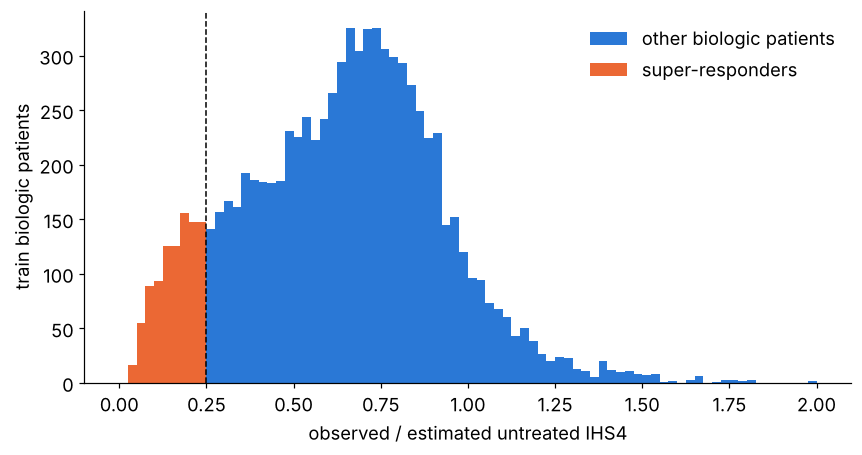

super-responders: 953 of 8548 = 11.1% (brief: roughly 1 in 8 = 12.5%)
median observed / untreated ratio: 0.65


In [3]:
lab = pd.DataFrame({"y": y.loc[BIO["train"]], "cf": CF["train"]})
lab["ratio"] = lab.y / lab.cf
lab["sr"] = (lab.ratio < 0.25).astype(int)

fig, ax = plt.subplots(figsize=(8, 4.3))
bins = np.linspace(0, 2, 81)
ax.hist(lab.ratio.clip(0, 2)[lab.sr == 0], bins=bins, color=PAL[0], label="other biologic patients")
ax.hist(lab.ratio.clip(0, 2)[lab.sr == 1], bins=bins, color=PAL[1], label="super-responders")
ax.axvline(0.25, color="black", ls="--", lw=1)
ax.set_xlabel("observed / estimated untreated IHS4"); ax.set_ylabel("train biologic patients"); ax.legend()
plt.tight_layout(); plt.show()
print(f"super-responders: {lab.sr.sum()} of {len(lab)} = {lab.sr.mean():.1%} (brief: roughly 1 in 8 = 12.5%)")
print(f"median observed / untreated ratio: {lab.ratio.median():.2f}")

**Results.**

* **11.1 % of biologic patients are super-responders** (953 of 8,548), close to the "roughly 1 in 8"
  (12.5 %) stated in the brief. This supports the untreated estimate.
* The typical patient sits at about 65 % of their untreated level.
* Super-responders form the left tail of a continuous distribution, not a separate group. Patients near
  the 0.25 line are the uncertain ones, because the untreated estimate itself has an error of about 2.5
  points.

## 3. Does a dedicated model forecast biologic patients better? (2a)

We compare, on the biologic patients only and on the same folds as Exercise 1:
* the Exercise 1 predictions;
* a **dedicated** LightGBM trained only on biologic patients, with three extra features: the untreated
  estimate `cf`, the year-before IHS4 at the first biologic, and the current level relative to `cf`;
* the average of the two.

In [4]:
def bio_frame(split):
    f = F[split].loc[BIO[split], FEATS].copy()
    f["cf"] = CF[split]
    f["pre_bio_level"] = XPRE[split].pre_mean_corr.values
    f["level_vs_cf"] = f.eb_level / f.cf.clip(lower=0.5)
    return f

B = {s: bio_frame(s) for s in ["train", "train_sim", "test_1", "test_2"]}
BFEATS = list(B["train"].columns)
yb = y.loc[BIO["train"]].values
fb = oof1.fold.loc[BIO["train"]].values
wb = oof1.w_test2.loc[BIO["train"]].values

ded_o, ded_s, its_b = np.zeros(len(yb)), np.zeros(len(yb)), []
for k in range(5):
    a, b = fb != k, fb == k
    dval = lgb.Dataset(pd.concat([B["train"][b], B["train_sim"][b]]), np.r_[yb[b], yb[b]])   # original + thinned validation rows
    m = lgb.train({**PARAMS, "min_data_in_leaf": 30}, lgb.Dataset(B["train"][a], yb[a]), 4000, valid_sets=[dval],
                  callbacks=[lgb.early_stopping(200, verbose=False)])
    ded_o[b] = m.predict(B["train"][b], num_iteration=m.best_iteration)
    ded_s[b] = m.predict(B["train_sim"][b], num_iteration=m.best_iteration); its_b.append(m.best_iteration)

ex1_o, ex1_s = oof1.pred_orig.loc[BIO["train"]].values, oof1.pred_sim.loc[BIO["train"]].values
sc = lambda po, ps: {"MAE test_1 proxy": np.abs(po - yb).mean(), "MAE pseudo-test_2": np.average(np.abs(ps - yb), weights=wb)}
res2a = pd.DataFrame({"Exercise 1 model": sc(ex1_o, ex1_s), "dedicated model": sc(ded_o, ded_s),
                      "average of both": sc((ex1_o + ded_o) / 2, (ex1_s + ded_s) / 2)}).T
CHOICE = res2a.mean(axis=1).idxmin()
print("chosen for 2a:", CHOICE)
res2a.round(3)

chosen for 2a: average of both


,MAE test_1 proxy,MAE pseudo-test_2
Exercise 1 model,1.167,1.310
dedicated model,1.166,1.295
average of both,1.152,1.286


**Results.**

* The dedicated model alone is as good as Exercise 1 (1.166 vs 1.167), and better on the pseudo‑test_2
  (1.295 vs 1.310).
* **Averaging the two is best on both** (1.152 / 1.286), so the average is submitted for 2a.
* The gain is small because Exercise 1 already handles biologic patients well.

## 4. Can super-responders be spotted before, early in, or after treatment?

We train three classifiers with growing information:
* **Before treatment:** the state in the year before the first biologic, demographics, drug and line.
* **Early in treatment:** + the response in months 1–6 of the current biologic, relative to the year
  before and to `cf`.
* **Now:** all current features + `cf` + the 2a forecast. This one produces `super_responder_prob`.

Scored out of fold with AUC (ranking quality) and average precision (AP; chance level = the prevalence).

In [5]:
PRE_COLS = ["hist_days", "pre_n_visits", "pre_n_scored", "pre_mean_corr", "pre_mean_sched", "pre_max_score", "pre_n_flare_visits",
            "pre_ewm_corr", "pre_neff", "mean_corr_before", "pre_n_abx", "pre_n_surg", "hurley", "sex_female", "age_at_t0",
            "years_dx_at_t0", "bmi"]

def info_sets(split, pred_2a):
    cur = F[split].loc[BIO[split]]
    before = XPRE[split][PRE_COLS].set_axis(BIO[split]).assign(cf=CF[split].values)
    for c in ["bio_drug", "bio_line", "n_prior_bio", "diagnostic_delay", "ethnicity", "smoking"]:
        before[c] = cur[c].values
    early = before.assign(bio_pre_mean=cur.bio_pre_mean.values, bio_early_mean=cur.bio_early_mean.values,
                          bio_early_ratio=cur.bio_early_ratio.values, early_vs_cf=(cur.bio_early_mean / CF[split].clip(lower=0.5)).values)
    now = B[split].assign(pred_2a=pred_2a, pred_vs_cf=pred_2a / B[split].cf.clip(lower=0.5))
    return {"before treatment": before, "early in treatment": early, "now": now}

pick = lambda e1, ded: {"Exercise 1 model": e1, "dedicated model": ded, "average of both": (e1 + ded) / 2}[CHOICE]
S = info_sets("train", pick(ex1_o, ded_o))
srl = lab.sr.values
CLF = dict(objective="binary", learning_rate=0.03, num_leaves=15, min_data_in_leaf=40, feature_fraction=0.8,
           bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=SEED)

def boot_auc(t, p, n=500):
    r = np.random.default_rng(SEED); out = []
    for _ in range(n):
        i = r.integers(0, len(t), len(t)); out.append(roc_auc_score(t[i], p[i]))
    return np.percentile(out, [2.5, 97.5])

oof_clf, n_trees, rows = {}, {}, {}
for name, X in S.items():
    p, its = np.zeros(len(srl)), []
    for k in range(5):
        a, b = fb != k, fb == k
        m = lgb.train(CLF, lgb.Dataset(X[a], srl[a]), 3000, valid_sets=[lgb.Dataset(X[b], srl[b])],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
        p[b] = m.predict(X[b], num_iteration=m.best_iteration); its.append(m.best_iteration)
    oof_clf[name], n_trees[name] = p, int(np.mean(its) * 1.1)
    lo, hi = boot_auc(srl, p)
    rows[name] = {"AUC": roc_auc_score(srl, p), "95% CI": f"{lo:.2f}–{hi:.2f}", "AP": average_precision_score(srl, p)}
recent = (F["train"].loc[BIO["train"], "days_on_bio"] < 183).values
for name, p in oof_clf.items():
    rows[name]["AUC, started <6 months ago"] = roc_auc_score(srl[recent], p[recent])
print(f"prevalence {srl.mean():.3f} (= chance-level AP) | recent starters: {recent.sum()}, prevalence {srl[recent].mean():.3f}")
pd.DataFrame(rows).T.round(3)

prevalence 0.111 (= chance-level AP) | recent starters: 843, prevalence 0.060


,AUC,95% CI,AP,"AUC, started <6 months ago"
before treatment,0.749604,0.74–0.76,0.225452,0.814146
early in treatment,0.836229,0.82–0.85,0.439727,0.810656
now,0.975997,0.97–0.98,0.879503,0.819024


**Results.**

* **Before treatment: AUC 0.75**, with average precision 0.23, twice the chance level of 0.11.
  Super-responders can be partly anticipated when the biologic is prescribed.
* **Early in treatment: AUC 0.84** (AP 0.44). A few months of response identify most of them.
* **Now: AUC 0.98** (AP 0.88). Near-perfect identification today, but partly circular, because the label
  is built from the same on-treatment record.
* **Patients who started less than 6 months ago** are rarer super-responders (6.0 %), consistent with an
  effect that builds over time. All three models reach AUC ≈ 0.81 for them: there is no early response to
  use yet.

## 5. What sets super-responders apart?

Two views: super-responder rates by Hurley stage and treatment line (A), and the SHAP importance of the
**before-treatment** classifier (B), i.e. what was knowable when deciding to prescribe. The table below
gives the standardised mean differences (SMD) between super-responders and other biologic patients.

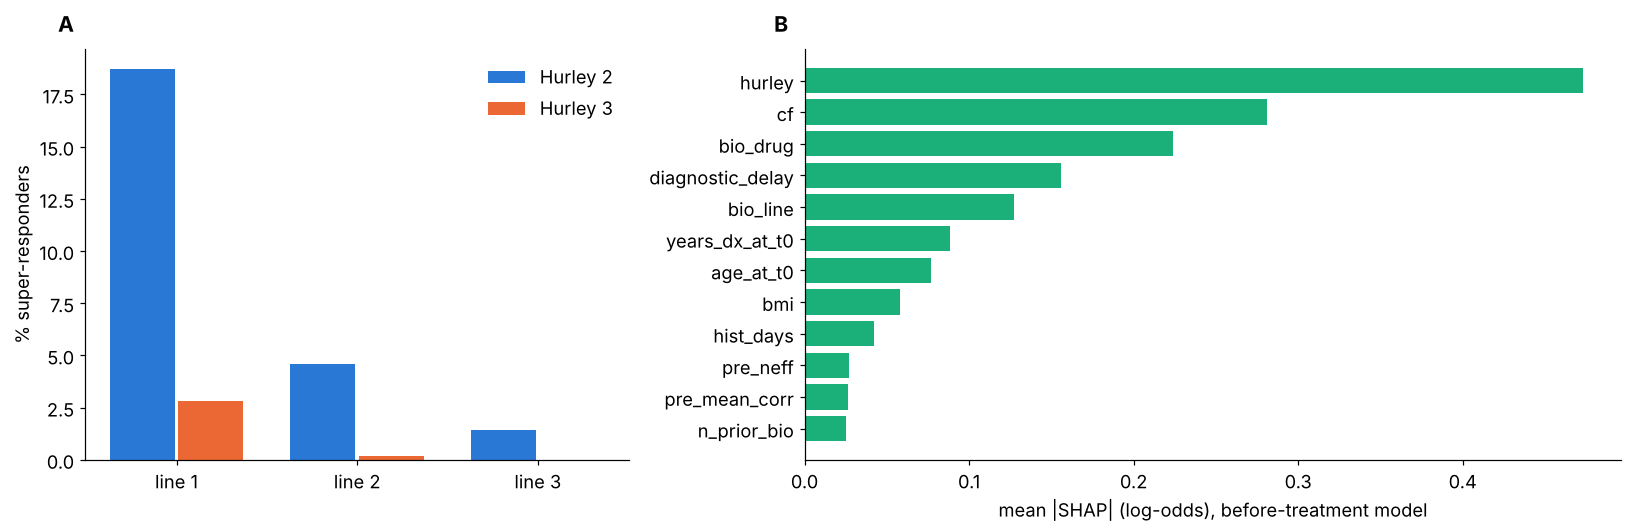

super-responder rate by drug × line:
bio_line         1      2      3
bio_drug                        
Adalimumab   0.134  0.000    NaN
Bimekizumab  0.000  0.030  0.006
Secukinumab  0.333  0.027  0.011

by sex: {0: 0.109, 1: 0.112} | by practitioner biologic-use tercile: {'low': 0.104, 'mid': 0.112, 'high': 0.118}


,super-responders,others,SMD
hurley,2.07,2.38,-0.81
cf,10.23,12.54,-0.75
mean_corr_before,9.47,11.84,-0.57
pre_mean_corr,9.54,11.92,-0.56
pre_ewm_corr,9.57,11.94,-0.56
n_prior_bio,0.05,0.28,-0.54
bio_line,1.05,1.28,-0.54
pre_mean_sched,9.19,11.89,-0.53
pre_max_score,14.25,17.47,-0.49
diagnostic_delay,3.73,4.59,-0.29


In [6]:
final_clf = {n: lgb.train(CLF, lgb.Dataset(X, srl), n_trees[n]) for n, X in S.items()}
Xb = S["before treatment"]
impA = pd.Series(np.abs(final_clf["before treatment"].predict(Xb, pred_contrib=True)[:, :-1]).mean(0), Xb.columns).sort_values()

cur_tr = F["train"].loc[BIO["train"]]
rate = pd.crosstab(cur_tr.hurley, cur_tr.bio_line.astype(int), values=srl, aggfunc="mean")
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [0.8, 1.2]})
xx = np.arange(rate.shape[1])
for i, (h, c) in enumerate(zip(rate.index, [PAL[0], PAL[1]])):
    ax[0].bar(xx + (i - 0.5) * 0.38, rate.loc[h].values * 100, 0.36, color=c, label=f"Hurley {int(h)}")
ax[0].set_xticks(xx, [f"line {l}" for l in rate.columns]); ax[0].set_ylabel("% super-responders"); ax[0].legend()
top = impA.tail(12)
ax[1].barh(top.index, top.values, color=PAL[2]); ax[1].set_xlabel("mean |SHAP| (log-odds), before-treatment model")
letters(ax); plt.tight_layout(); plt.show()

num = Xb.select_dtypes("number")
smd = ((num[srl == 1].mean() - num[srl == 0].mean()) / np.sqrt((num[srl == 1].var() + num[srl == 0].var()) / 2)).dropna()
print("super-responder rate by drug × line:")
print(pd.crosstab(cur_tr.bio_drug.astype(str), cur_tr.bio_line.astype(int), values=srl, aggfunc="mean").round(3))
print("\nby sex:", pd.Series(srl).groupby(cur_tr.sex_female.values).mean().round(3).to_dict(),
      "| by practitioner biologic-use tercile:", pd.Series(srl).groupby(pd.qcut(cur_tr.pr_bio_rate, 3, labels=["low", "mid", "high"]).values, observed=True).mean().round(3).to_dict())
pd.DataFrame({"super-responders": num[srl == 1].mean(), "others": num[srl == 0].mean(), "SMD": smd}).dropna().reindex(smd.abs().sort_values(ascending=False).index).head(10).round(2)

**Results.** The drivers are clinically plausible. Biologics work best before disease becomes advanced and
tunnels form, and when used first.

* **Hurley stage:** about 19 % super-responders among Hurley 2 patients on their first biologic, under 3 %
  for Hurley 3 (A). This is the strongest before-treatment marker (B).
* **First-line treatment:** super-responders are almost always on their first biologic (SMD −0.54 for
  prior biologics).
* **Milder disease before treatment:** lower untreated estimate (10.2 vs 12.5) and lower IHS4 in the year
  before (9.5 vs 11.9).
* **Earlier treatment:** shorter diagnostic delay (3.7 vs 4.6 years) and younger age at the first
  biologic.

Two cautions:
* **Drug vs line.** The drug × line table shows adalimumab is essentially always first line. The higher
  rate on adalimumab cannot be separated from the first-line effect.
* **Artefact checks.** Rates do not differ by sex (10.9 % vs 11.2 %) or by how often the practitioner
  prescribes biologics (10–12 %), so the signal is not a prescribing habit.

## 6. Submission

For each test biologic patient: the 2a forecast chosen above (the dedicated model is refitted on all
train biologic patients, 3 seeds) and `super_responder_prob` from the "now" classifier.

In [7]:
ded_models = [lgb.train({**PARAMS, "min_data_in_leaf": 30, "seed": SEED + s}, lgb.Dataset(B["train"], yb), int(np.mean(its_b) * 1.1)) for s in range(3)]
out = []
for s in ["test_1", "test_2"]:
    ex1 = pred1.reindex(BIO[s]).values
    ded = np.mean([m.predict(B[s]) for m in ded_models], axis=0)
    p2a = np.clip(pick(ex1, ded), 0, None)
    prob = final_clf["now"].predict(info_sets(s, p2a)["now"][S["now"].columns])
    out.append(pd.DataFrame({"pred_avg_ihs4_next6": p2a, "super_responder_prob": prob}, index=BIO[s]))
out = pd.concat(out)

tmpl = pd.read_csv(DATA / "evaluation_templates" / "answers_teamName_exercise2.csv")
sub = tmpl[["patient_id"]].join(out, on="patient_id")
assert sub.notna().all().all() and len(sub) == len(tmpl)
sub.round(4).to_csv(SUB / f"answers_{TEAM_NAME}_exercise2.csv", index=False)
lab.to_parquet(WORK / "sr_labels_train.parquet")
pd.DataFrame({"sr_prob_before": oof_clf["before treatment"]}, index=BIO["train"]).to_parquet(WORK / "oof_ex2.parquet")
print(sub.shape, "->", SUB / f"answers_{TEAM_NAME}_exercise2.csv")
print("mean super_responder_prob:", round(sub.super_responder_prob.mean(), 3), "| mean forecast:", round(sub.pred_avg_ihs4_next6.mean(), 2))

(4140, 3) -> submissions/answers_skincaredivas_exercise2.csv
mean super_responder_prob: 0.11 | mean forecast: 8.06


**Results.** The file covers all 4,140 biologic test patients. The mean super-responder probability (0.11) matches
the training prevalence, and the mean forecast (8.1) matches the level of biologic patients in train.